<a href="https://colab.research.google.com/github/haodashi123/MS-GenAI-Colab-Demo/blob/main/Demo1_%E5%95%86%E4%B8%9A%E5%88%86%E6%9E%90%E4%B8%8EIPA%E7%9F%A9%E9%98%B5_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. 查看 Colab 分配的 GPU 型号与显存状态
!nvidia-smi

import torch
print("-" * 50)
print(f"PyTorch 版本: {torch.__version__}")
print(f"CUDA GPU 是否可用: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"当前挂载计算设备: {torch.cuda.get_device_name(0)}")
    print(f"可用显存总容量: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Wed Oct 21 09:31:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# @title 🎛️ 管科商业评论数据生成器（支持右侧交互调参）
import pandas as pd
import numpy as np
from google.colab import data_table

# 激活 Colab 专属交互式表格模式
data_table.enable_dataframe_formatter()

# Colab 专属表单语法：可以直接在右侧拖动滑块或选择下拉框
行业场景 = "智能新能源汽车" # @param ["智能新能源汽车", "跨境电商供应链", "SaaS企业服务"]
样本数量 = 60 # @param {type:"slider", min:20, max:100, step:10}
随机种子 = 42 # @param {type:"number"}

np.random.seed(随机种子)

# 构建管科分析维度与模拟非结构化评论
dimensions = ["智驾算法体验", "电池续航表现", "座舱语音交互", "售后维保响应", "底盘驾控质感", "充电网络覆盖"]
sample_reviews = {
    "智驾算法体验": ("高速NOA领航非常丝滑，变道果断", "城区智驾偶发幽灵刹车，让人紧张"),
    "电池续航表现": ("扎实续航，冬季达成率超出预期", "高速掉电太快，冬季续航缩水严重"),
    "座舱语音交互": ("大模型语音助手能听懂复杂连续指令", "车机偶尔卡顿，方言识别率有待提高"),
    "售后维保响应": ("服务中心响应迅速，上门取送车方便", "配件等待周期太长，客服推诿问题"),
    "底盘驾控质感": ("空悬滤震高级，过弯侧倾抑制极佳", "后排颠簸感明显，胎噪控制一般"),
    "充电网络覆盖": ("超充桩功率拉满，15分钟补能无焦虑", "节假日高速服务区排队，部分桩故障")
}

# 设定各维度的真实分布均值（用于模拟真实商业差异）
true_satisfaction = {"智驾算法体验": 0.78, "电池续航表现": 0.42, "座舱语音交互": 0.85,
                     "售后维保响应": 0.35, "底盘驾控质感": 0.72, "充电网络覆盖": 0.48}
mention_weights = [0.22, 0.25, 0.15, 0.18, 0.08, 0.12]

rows = []
for i in range(样本数量):
    dim = np.random.choice(dimensions, p=mention_weights)
    is_positive = np.random.rand() < true_satisfaction[dim]
    text = sample_reviews[dim][0] if is_positive else sample_reviews[dim][1]
    rows.append({
        "评论ID": f"REV-{1001+i}",
        "所属行业": 行业场景,
        "核心业务维度": dim,
        "用户原始评论文本": text,
        "用户互动热度": int(np.random.exponential(scale=50) + 10)
    })

df_reviews = pd.DataFrame(rows)
print(f"✅ 已生成【{行业场景}】共 {len(df_reviews)} 条样本，请点击下方表格体验 Colab 交互式筛选与排序：")
df_reviews

✅ 已生成【SaaS企业服务】共 60 条样本，请点击下方表格体验 Colab 交互式筛选与排序：


,评论ID,所属行业,核心业务维度,用户原始评论文本,用户互动热度
0,REV-1001,SaaS企业服务,电池续航表现,高速掉电太快，冬季续航缩水严重,75
1,REV-1002,SaaS企业服务,座舱语音交互,大模型语音助手能听懂复杂连续指令,18
2,REV-1003,SaaS企业服务,智驾算法体验,城区智驾偶发幽灵刹车，让人紧张,55
3,REV-1004,SaaS企业服务,售后维保响应,服务中心响应迅速，上门取送车方便,185
4,REV-1005,SaaS企业服务,底盘驾控质感,空悬滤震高级，过弯侧倾抑制极佳,20
5,REV-1006,SaaS企业服务,智驾算法体验,高速NOA领航非常丝滑，变道果断,47
6,REV-1007,SaaS企业服务,电池续航表现,扎实续航，冬季达成率超出预期,57
7,REV-1008,SaaS企业服务,智驾算法体验,高速NOA领航非常丝滑，变道果断,32
8,REV-1009,SaaS企业服务,电池续航表现,高速掉电太快，冬季续航缩水严重,21
9,REV-1010,SaaS企业服务,座舱语音交互,大模型语音助手能听懂复杂连续指令,12


In [ ]:
# @title 🚀 调用 GPU 加载开源大模型进行情感极性与置信度评分
from transformers import pipeline
import torch

# 自动绑定 Colab 分配的 GPU (device=0)
device_id = 0 if torch.cuda.is_available() else -1

print("正在将多语言情感分析大模型加载至 Colab GPU 显存...")
sentiment_llm = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    device=device_id
)

# 批量对评论文本进行 GPU 加速推理
texts = df_reviews["用户原始评论文本"].tolist()
results = sentiment_llm(texts)

# 将模型输出的非结构化标签转化为管科定量满意度得分 (0~100分)
scores = []
labels = []
for res in results:
    label = res["label"]
    conf = res["score"]
    labels.append(label)
    if label == "positive":
        scores.append(round(50 + 50 * conf, 1))
    elif label == "negative":
        scores.append(round(50 - 50 * conf, 1))
    else:
        scores.append(50.0)

df_reviews["AI判定情感"] = labels
df_reviews["AI量化满意度(0-100)"] = scores

print("✅ GPU 大模型批量推理完成！前 10 条结构化量化结果如下：")
df_reviews.head(10)

正在将多语言情感分析大模型加载至 Colab GPU 显存...


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

✅ GPU 大模型批量推理完成！前 10 条结构化量化结果如下：


,评论ID,所属行业,核心业务维度,用户原始评论文本,用户互动热度,AI判定情感,AI量化满意度(0-100)
0,REV-1001,SaaS企业服务,电池续航表现,高速掉电太快，冬季续航缩水严重,75,negative,5.9
1,REV-1002,SaaS企业服务,座舱语音交互,大模型语音助手能听懂复杂连续指令,18,positive,85.5
2,REV-1003,SaaS企业服务,智驾算法体验,城区智驾偶发幽灵刹车，让人紧张,55,positive,85.7
3,REV-1004,SaaS企业服务,售后维保响应,服务中心响应迅速，上门取送车方便,185,positive,95.2
4,REV-1005,SaaS企业服务,底盘驾控质感,空悬滤震高级，过弯侧倾抑制极佳,20,positive,95.1
5,REV-1006,SaaS企业服务,智驾算法体验,高速NOA领航非常丝滑，变道果断,47,negative,27.2
6,REV-1007,SaaS企业服务,电池续航表现,扎实续航，冬季达成率超出预期,57,positive,89.6
7,REV-1008,SaaS企业服务,智驾算法体验,高速NOA领航非常丝滑，变道果断,32,negative,27.2
8,REV-1009,SaaS企业服务,电池续航表现,高速掉电太快，冬季续航缩水严重,21,negative,5.9
9,REV-1010,SaaS企业服务,座舱语音交互,大模型语音助手能听懂复杂连续指令,12,positive,85.5


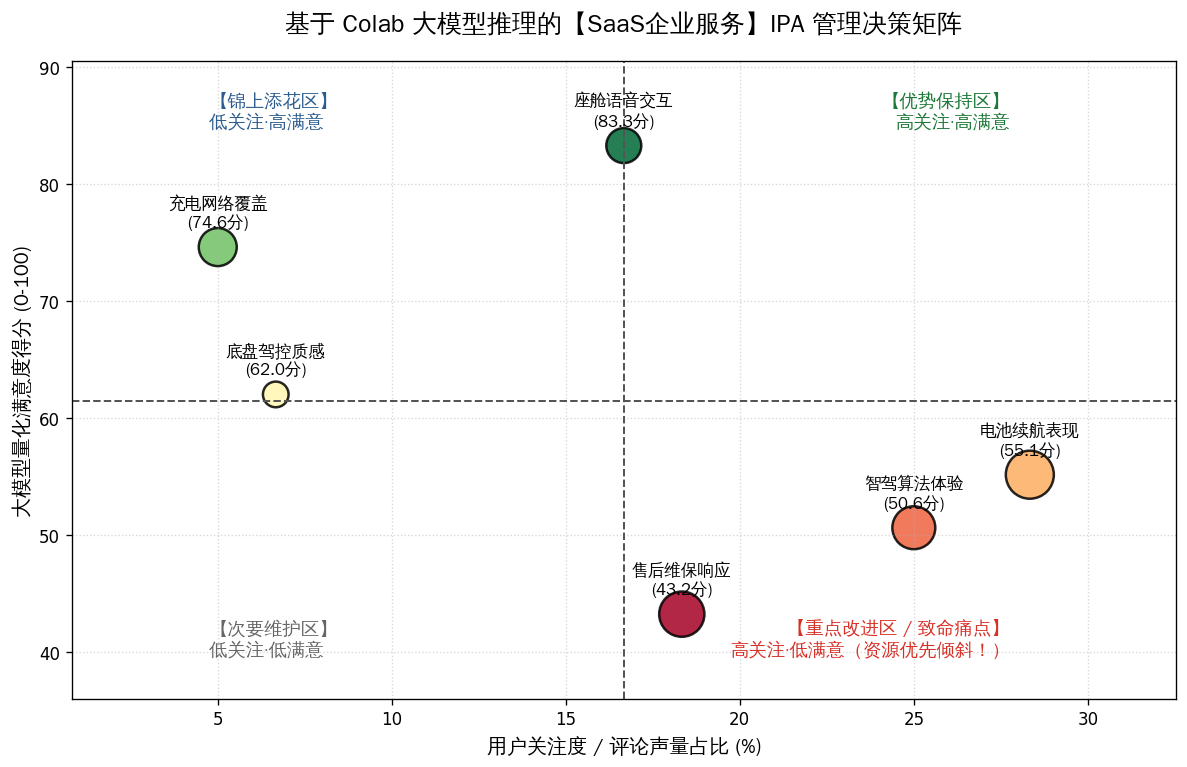

In [ ]:
# @title 📊 输出管科 IPA (Importance-Performance Analysis) 战略决策矩阵
import matplotlib.pyplot as plt
import numpy as np

# 解决 Colab 英文环境下的中文显示问题（使用系统自带或回退字体标签辅助）
!apt-get -qq install -y fonts-wqy-zenhei > /dev/null
import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc'
prop = fm.FontProperties(fname=font_path)

# 按业务维度聚合计算：声量关注度（Importance）与 AI 量化满意度均值（Performance）
ipa_summary = df_reviews.groupby("核心业务维度").agg(
    声量占比=("评论ID", lambda x: len(x) / len(df_reviews) * 100),
    平均满意度=("AI量化满意度(0-100)", "mean"),
    平均热度=("用户互动热度", "mean")
).reset_index()

fig, ax = plt.subplots(figsize=(10, 6.5), dpi=120)

# 绘制气泡图（气泡大小代表用户互动热度）
scatter = ax.scatter(
    ipa_summary["声量占比"],
    ipa_summary["平均满意度"],
    s=ipa_summary["平均热度"] * 12,
    c=ipa_summary["平均满意度"],
    cmap="RdYlGn",
    alpha=0.85,
    edgecolors="black",
    linewidth=1.5
)

# 计算十字分割线（均值基准线）
x_mean = ipa_summary["声量占比"].mean()
y_mean = ipa_summary["平均满意度"].mean()
ax.axvline(x_mean, color="#555555", linestyle="--", linewidth=1.2)
ax.axhline(y_mean, color="#555555", linestyle="--", linewidth=1.2)

# 为每个维度添加文字标注
for _, row in ipa_summary.iterrows():
    ax.annotate(
        f"{row['核心业务维度']}\n({row['平均满意度']:.1f}分)",
        (row["声量占比"], row["平均满意度"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontproperties=prop,
        fontsize=10,
        weight="bold"
    )

# 标注管科经典四象限管理策略
ax.text(ipa_summary["声量占比"].max()*0.98, ipa_summary["平均满意度"].max()*1.02,
        "【优势保持区】\n高关注·高满意", fontproperties=prop, fontsize=11, color="#1b7837", ha="right", weight="bold")
ax.text(ipa_summary["声量占比"].max()*0.98, ipa_summary["平均满意度"].min()*0.92,
        "【重点改进区 / 致命痛点】\n高关注·低满意（资源优先倾斜！）", fontproperties=prop, fontsize=11, color="#d73027", ha="right", weight="bold")
ax.text(ipa_summary["声量占比"].min()*0.95, ipa_summary["平均满意度"].max()*1.02,
        "【锦上添花区】\n低关注·高满意", fontproperties=prop, fontsize=11, color="#2b5c8f", ha="left")
ax.text(ipa_summary["声量占比"].min()*0.95, ipa_summary["平均满意度"].min()*0.92,
        "【次要维护区】\n低关注·低满意", fontproperties=prop, fontsize=11, color="#666666", ha="left")

ax.set_title(f"基于 Colab 大模型推理的【{行业场景}】IPA 管理决策矩阵", fontproperties=prop, fontsize=15, pad=18, weight="bold")
ax.set_xlabel("用户关注度 / 评论声量占比 (%)", fontproperties=prop, fontsize=12)
ax.set_ylabel("大模型量化满意度得分 (0-100)", fontproperties=prop, fontsize=12)
ax.grid(True, linestyle=":", alpha=0.5)
plt.margins(0.18)
plt.tight_layout()
plt.show()

In [ ]:
# 演示 Colab 最规范的企业级 API 密钥读取方式（绝不在代码中明文暴露 Key）
from google.colab import userdata
from google import genai

try:
    # 从 Colab 左侧安全密钥箱读取 API Key
    api_key = userdata.get('GEMINI_API_KEY')
    client = genai.Client(api_key=api_key)

    prompt = f"""
    你是一位管理科学与工程专家。根据以下汇总数据：
    {ipa_summary.to_dict(orient='records')}
    请用3条精炼要点给出针对性的供应链与产品改进建议。
    """
    response = client.models.generate_content(
        model="gemini-3.5-flash",
        contents=prompt
    )
    print(response.text)
except Exception as e:
    print("💡 演示提示：在左侧【🔑 Secrets】面板中添加 GEMINI_API_KEY 后即可一键生成管理咨询报告。")

基于数据分析，针对“电池续航”与“售后维保”高声量低满意度的严重卡脖子问题，以及“智驾算法”体验不佳的现状，从管理科学与供应链管理角度提供以下3条精炼建议：

### 1. 聚焦“电池-热管理”供应链协同，优化产品真实续航体验
* **数据诊断**：电池续航声量（28.3%）与热度（69.2）均为最高，但满意度仅55.1分，属于核心业务瓶颈。
* **改进建议**：
  * **产品端**：重点优化BMS（电池管理系统）控制策略与高能效热管理系统架构，提升低容/低温环境下的真实续航达成率。
  * **供应链端**：深化与 Tier-1 电池厂商的战略协同，引入高能量密度电芯；同时推行供应商质量管理（SQE）前置，建立电芯衰减与一致性的端到端追溯体系。

### 2. 重构售后备件供应链，撬动“服务响应”满意度逆袭
* **数据诊断**：售后维保响应声量占18.3%，但满意度仅43.2分（全维度最低），属于严重拖累品牌口碑的运营风险点。
* **改进建议**：
  * **供应链端**：应用大数据进行区域备件需求预测，建立“中心仓-区域前置仓”两级敏捷物流体系，大幅缩短易损件与事故件的物流履约周期。
  * **产品/服务端**：推动产品模块化与可维修性设计（DFM），降低维修门槛；同时标准化售后服务流程（SOP），建立端到端工单超时预警机制。

### 3. 强化智驾“软硬协同”敏捷迭代，固化座舱体验优势
* **数据诊断**：智驾算法声量高（25.0%）但满意度仅50.6分；座舱语音满意度高达83.3分（优势项）。
* **改进建议**：
  * **产品端**：针对智驾体验，建立“用户反馈-数据打标-算法训练-OTA推送”的高频闭环；针对座舱语音，固化语音芯片与AI大模型的长板优势，打造差异化护城河。
  * **供应链端**：搭建敏捷的芯片/传感器硬件供应链体系，打通底层硬件接口与上层算法的深度适配，保障智能化硬件供应韧性的同时降低接口兼容故障率。


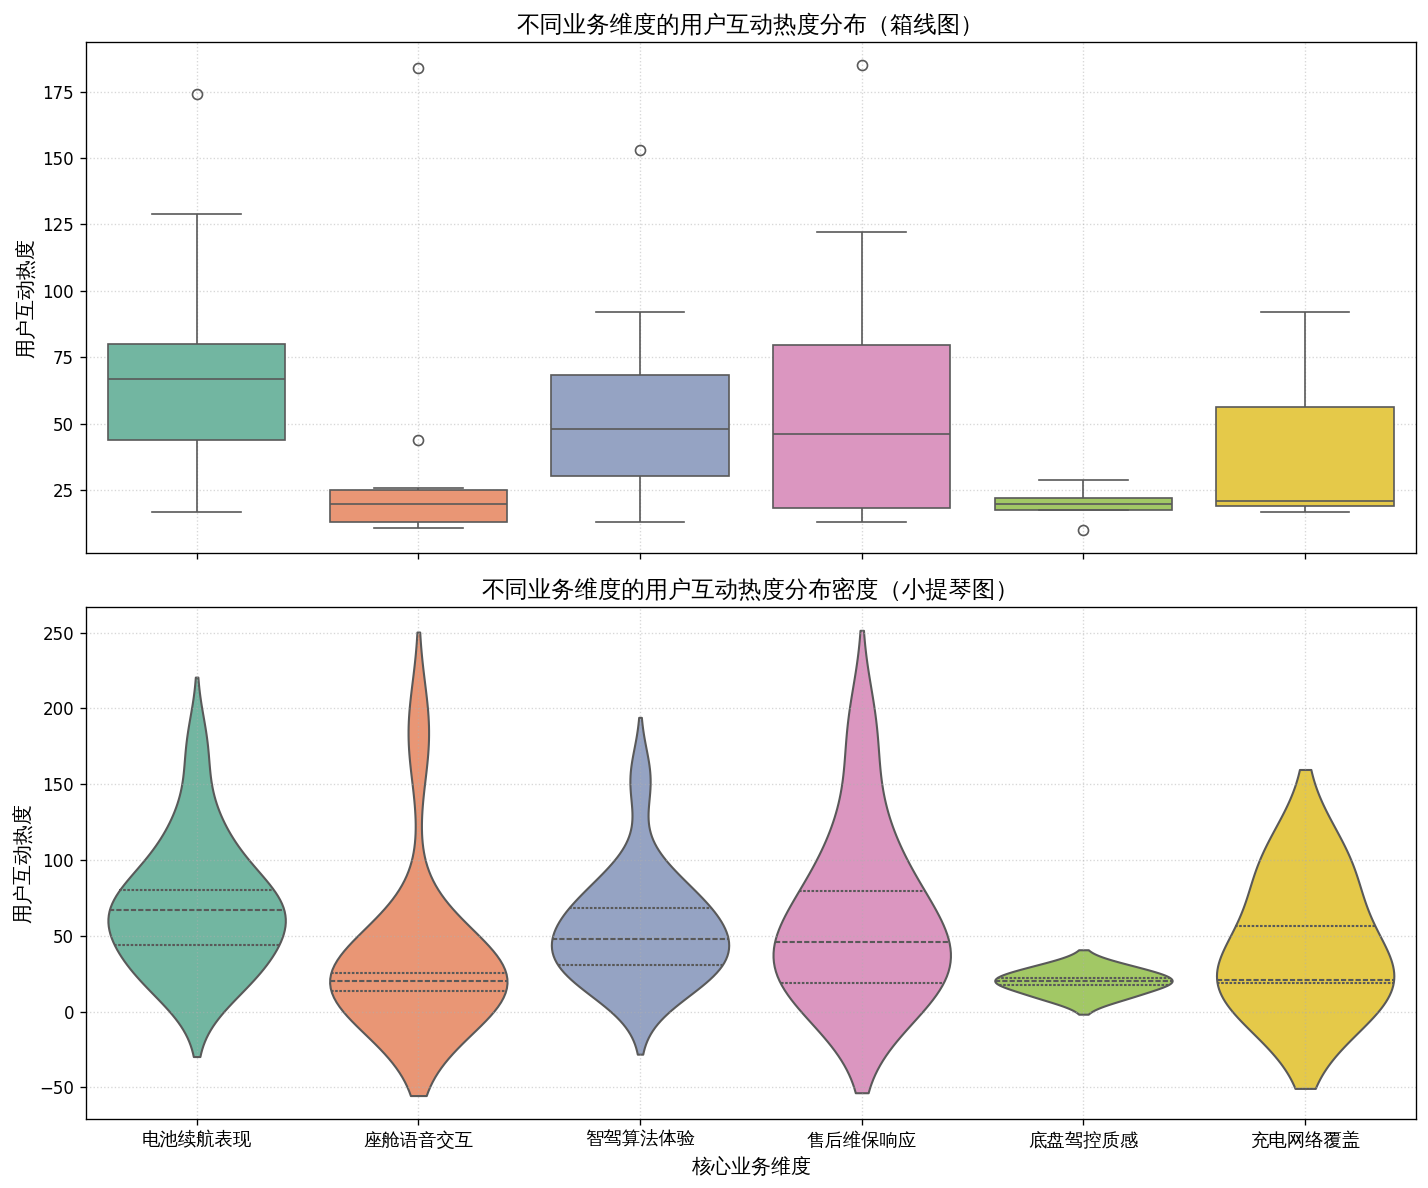

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 设置支持中文的字体属性
import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc'
prop = fm.FontProperties(fname=font_path)

# 设定画布大小
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True, dpi=120)

# 1. 箱线图 (Boxplot) - 展现中位数、四分位数及异常值
sns.boxplot(
    ax=axes[0],
    x="核心业务维度",
    y="用户互动热度",
    data=df_reviews,
    palette="Set2",
    hue="核心业务维度",
    legend=False
)
axes[0].set_title("不同业务维度的用户互动热度分布（箱线图）", fontproperties=prop, fontsize=14, weight='bold')
axes[0].set_ylabel("用户互动热度", fontproperties=prop, fontsize=12)
axes[0].grid(True, linestyle=":", alpha=0.5)

# 2. 小提琴图 (Violin Plot) - 展现数据密度分布
sns.violinplot(
    ax=axes[1],
    x="核心业务维度",
    y="用户互动热度",
    data=df_reviews,
    palette="Set2",
    hue="核心业务维度",
    legend=False,
    inner="quart"
)
axes[1].set_title("不同业务维度的用户互动热度分布密度（小提琴图）", fontproperties=prop, fontsize=14, weight='bold')
axes[1].set_xlabel("核心业务维度", fontproperties=prop, fontsize=12)
axes[1].set_ylabel("用户互动热度", fontproperties=prop, fontsize=12)
axes[1].grid(True, linestyle=":", alpha=0.5)

# 调整 X 轴标签字体及角度以防重叠
for label in axes[1].get_xticklabels():
    label.set_fontproperties(prop)
    label.set_fontsize(11)

plt.tight_layout()
plt.show()